In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

from torchvision import datasets, transforms

In [3]:
torch.manual_seed(42)

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


In [5]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [6]:
!unzip -q "/content/drive/MyDrive/dsetCNNassignment.zip" -d "/content/dataset"


In [ ]:
# performing image transformations (this will Resize image to 128x128 and convert into PyTorch Tensors)
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(), # this automatically scales pixel values from 0-255 to 0.0-1.0
])

In [ ]:
# Loading data
train_data = datasets.ImageFolder(root='/content/dataset/afhq/train', transform=transform)
val_data = datasets.ImageFolder(root='/content/dataset/afhq/val', transform=transform)

In [ ]:
# DataLoaders for feeding images into batches of 32
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)

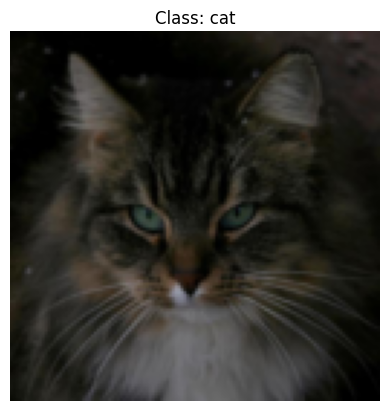

In [ ]:
import matplotlib.pyplot as plt

# index 0 is pointing to 1st image
index = 0
image, label = train_data[index]

# Rearrange dimensions from (C, H, W) to (H, W, C) for Matplotlib
plt.imshow(image.permute(1, 2, 0))
plt.title(f"Class: {train_data.classes[label]}")
plt.axis('off')
plt.show()

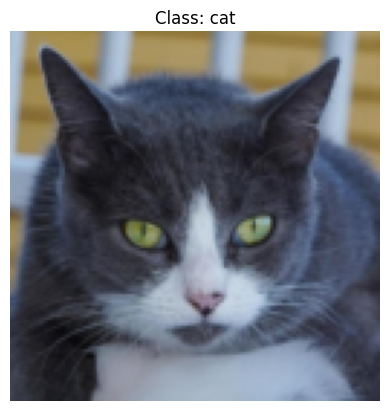

In [ ]:
import matplotlib.pyplot as plt

index = 3
image, label = train_data[index]

plt.imshow(image.permute(1, 2, 0))
plt.title(f"Class: {train_data.classes[label]}")
plt.axis('off')
plt.show()

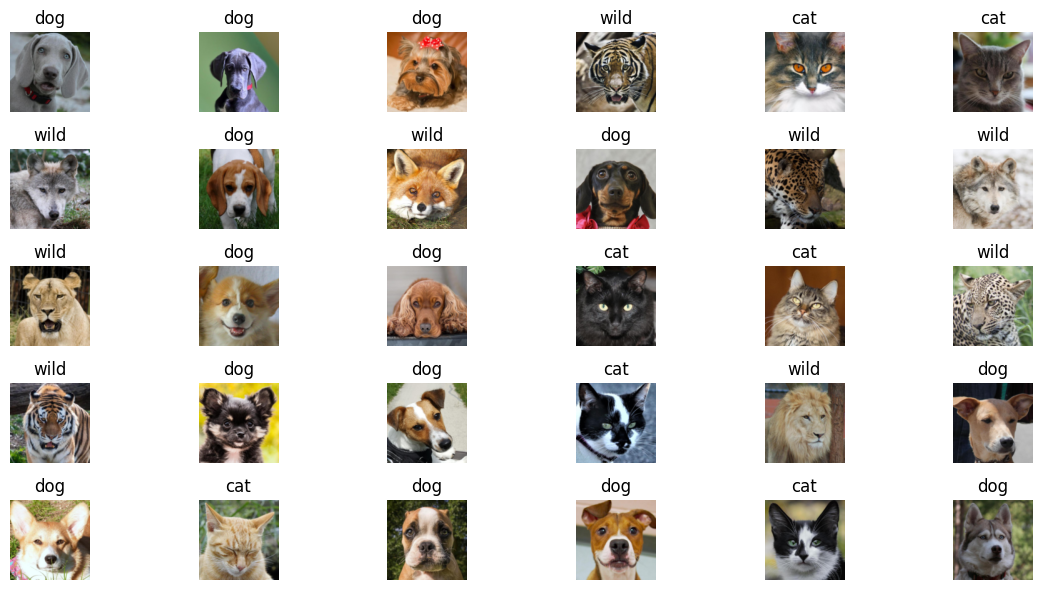

In [ ]:
import matplotlib.pyplot as plt

# Grab one batch of 32 images from your DataLoader
images, labels = next(iter(train_loader))

# 5x6 grid to show 30 images
fig, axes = plt.subplots(5, 6, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    # Converting tensor shape for plotting
    img = images[i].permute(1, 2, 0)
    ax.imshow(img)
    ax.set_title(train_data.classes[labels[i]])
    ax.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
# classes in dataset are
print("Classes found:", train_data.classes)

Classes found: ['cat', 'dog', 'wild']


In [ ]:
class AnimalCNN(nn.Module):
    def __init__(self):
        super(AnimalCNN, self).__init__()

        # Convolutional layers (feature extraction)
        self.conv_layers = nn.Sequential(
            # Block 1: Input 3 color channels (RGB) -> 32 filters
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2), # Image becomes 64x64

            # Block 2: 32 -> 64 filters
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # Image becomes 32x32

            # Block 3: 64 -> 128 filters
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # Image becomes 16x16
        )
# ------------feature extraction complete----------------------

        # Fully connected layers (it makes the final classification decision)
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 128),
            nn.ReLU(),
            nn.Linear(128, 3)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

model = AnimalCNN().to(device)


In [ ]:
# Loss function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10

for epoch in range(epochs):
    model.train() # model set to training mode
    running_loss = 0.0

    for images, labels in train_loader:
        # data moved to gpu
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {running_loss/len(train_loader):.4f}")

print("Training Complete!")


Epoch [1/10] - Loss: 0.4347
Epoch [2/10] - Loss: 0.1382
Epoch [3/10] - Loss: 0.0806
Epoch [4/10] - Loss: 0.0602
Epoch [5/10] - Loss: 0.0439
Epoch [6/10] - Loss: 0.0287
Epoch [7/10] - Loss: 0.0185
Epoch [8/10] - Loss: 0.0130
Epoch [9/10] - Loss: 0.0243
Epoch [10/10] - Loss: 0.0198
Training Complete!


In [ ]:
model.eval() # model set to evaluation mode
correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Validation Accuracy: {accuracy:.2f}%")


Validation Accuracy: 96.80%


In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad(): # Disable gradient calculation for faster testing
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Validation Accuracy: {accuracy:.2f}%")

Validation Accuracy: 99.62%


no overfitting observed

In [ ]:
import torch

torch.save(model.state_dict(), 'animal_cnn_weights.pth')
torch.save(model.state_dict(), '/content/drive/MyDrive/animal_cnn_weights.pth')
print("Model saved safely!")


Model saved safely!


In [ ]:
!pip install -q gradio

import gradio as gr
import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

classes = ['Cat', 'Dog', 'Wild']

def predict_animal(input_image):
    if input_image is None:
        return None

    image = input_image.convert("RGB")
    img_tensor = transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        outputs = model(img_tensor)
        probabilities = F.softmax(outputs, dim=1)[0]
    return {classes[i]: float(probabilities[i]) for i in range(3)}

interface = gr.Interface(
    fn=predict_animal,
    inputs=gr.Image(type="pil", label="Upload an Animal Face Photo"),
    outputs=gr.Label(num_top_classes=3, label="Model Prediction"),
    title="🐾 Animal Face Classifier (CNN)",
    description="Upload a clear photo of a Cat, Dog, or Wild Animal (tiger, lion, wolf, fox) to see the PyTorch CNN prediction."
)

interface.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://1ec77a6184718bc2a5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
